# Data Preparation


In [1]:
# Cell 01 - Import libraries, set configuration, and prepare Part-B output folders

# ============================================================
# 1. Basic Python libraries
# ============================================================
# os       -> helps check CPU count and environment
# json     -> saves dataset configuration for other notebooks
# random   -> controls Python randomness
# shutil   -> later used to zip/share output files
# Path     -> cleaner file/folder path handling
import os
import json
import random
import shutil
from pathlib import Path


# ============================================================
# 2. Data and numeric libraries
# ============================================================
# numpy  -> numerical arrays
# pandas -> CSV loading/saving and split tables
import numpy as np
import pandas as pd


# ============================================================
# 3. Image and visualization libraries
# ============================================================
# PIL is RGB-friendly and easy for reading images.
# matplotlib is used for sanity visualizations.
from PIL import Image
import matplotlib.pyplot as plt


# ============================================================
# 4. PyTorch libraries
# ============================================================
# torch Dataset/DataLoader will be used to prepare model-ready batches.
import torch
from torch.utils.data import Dataset, DataLoader


# ============================================================
# 5. Albumentations for image/mask augmentation
# ============================================================
# Albumentations keeps image and mask transforms synchronized.
# ToTensorV2 converts NumPy images/masks into PyTorch tensors.
import albumentations as A
from albumentations.pytorch import ToTensorV2


# ============================================================
# 6. Reproducibility
# ============================================================
# Fixed seed makes random operations more repeatable.
# Important: we are NOT creating a new split, but transforms still use randomness.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# If Kaggle GPU is available, seed CUDA too.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 7. Dataset configuration
# ============================================================
# This dataset name is for reporting and saved config files.
DATASET_NAME = "Moroccan Landing Site Segmentation V2"

# Part A used binary semantic segmentation:
# 0 = background
# 1 = landing site
NUM_CLASSES = 2

CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

# Use the same image size style as Part A.
# If your Part-A NB0/NB1 used another size, update this value.
IMAGE_SIZE = 256

# Batch size here is only for loader checking and sanity visualization.
BATCH_SIZE = 16


# ============================================================
# 8. Kaggle folder paths
# ============================================================
# /kaggle/input contains attached datasets and notebook outputs.
INPUT_ROOT = Path("/kaggle/input")

# /kaggle/working is where Kaggle saves this notebook's outputs.
WORK_ROOT = Path("/kaggle/working")

# Main output folder for this Part-B Data Prep notebook.
OUTPUT_ROOT = WORK_ROOT / "PartB_NB0_DataPrep_outputs"

# Shared folder for all Part-B model notebooks:
# SimCLR, BYOL, MAE, DINOv2, and Final Comparison.
SHARED_ROOT = OUTPUT_ROOT / "partb_shared"

# Create folders if they do not exist.
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SHARED_ROOT.mkdir(parents=True, exist_ok=True)


# ============================================================
# 9. Device check
# ============================================================
# Data Prep can run on CPU, but we still check GPU for later notebooks.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ============================================================
# 10. Print setup summary
# ============================================================
print("Part B NB0 Data Prep setup complete.")
print("Dataset name:", DATASET_NAME)
print("Number of classes:", NUM_CLASSES)
print("Class names:", CLASS_ID_TO_NAME)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)

print("\nKaggle input root:", INPUT_ROOT)
print("Notebook output root:", OUTPUT_ROOT)
print("Shared output root:", SHARED_ROOT)

print("\nImportant:")
print("This notebook will reuse Part-A train/val/test splits.")
print("No new split should be created in Part B.")

Part B NB0 Data Prep setup complete.
Dataset name: Moroccan Landing Site Segmentation V2
Number of classes: 2
Class names: {0: 'background', 1: 'landing_site'}
Image size: 256
Batch size: 16
Device: cuda

Kaggle input root: /kaggle/input
Notebook output root: /kaggle/working/PartB_NB0_DataPrep_outputs
Shared output root: /kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared

Important:
This notebook will reuse Part-A train/val/test splits.
No new split should be created in Part B.


In [2]:
# Cell 02 - Show attached Kaggle inputs

print("Attached Kaggle inputs:")

for input_path in sorted(INPUT_ROOT.iterdir()):
    print(" -", input_path)

Attached Kaggle inputs:
 - /kaggle/input/datasets
 - /kaggle/input/notebooks


In [3]:
# Cell 03 - Find Part-A NB0 split file

# Search for the split file exported from Part A NB0.
split_candidates = sorted(INPUT_ROOT.rglob("all_splits.csv"))

assert split_candidates, (
    "ERROR: all_splits.csv not found. Add Part-A NB0 output: 438 ass 1."
)

# Prefer the file inside NB0_outputs/splits.
split_candidates = sorted(
    split_candidates,
    key=lambda path: (
        "NB0_outputs" not in str(path),
        "splits" not in str(path),
        len(str(path)),
    ),
)

SPLIT_FILE = split_candidates[0]

# This should point to the NB0_outputs folder.
NB0_OUTPUT_ROOT = SPLIT_FILE.parents[1]

print("SPLIT_FILE:", SPLIT_FILE)
print("NB0_OUTPUT_ROOT:", NB0_OUTPUT_ROOT)

SPLIT_FILE: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv
NB0_OUTPUT_ROOT: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs


In [4]:
# Cell 04 - Find Part-A helper file and raw Moroccan dataset

# Find optional helper file from Part A NB0.
common_candidates = sorted(INPUT_ROOT.rglob("segmentation_common.py"))

if common_candidates:
    COMMON_FILE = sorted(
        common_candidates,
        key=lambda path: (
            "NB0_outputs" not in str(path),
            "common" not in str(path),
            len(str(path)),
        ),
    )[0]
else:
    COMMON_FILE = None

# Find raw dataset folder.
dataset_roots = []

for candidate in INPUT_ROOT.rglob("dataset"):
    if (
        (candidate / "training" / "images").is_dir()
        and (candidate / "training" / "masks").is_dir()
        and (candidate / "testing" / "images").is_dir()
        and (candidate / "testing" / "masks").is_dir()
    ):
        dataset_roots.append(candidate)

assert dataset_roots, "ERROR: Raw Moroccan dataset folder not found."

DATA_ROOT = sorted(dataset_roots, key=lambda path: len(str(path)))[0]

print("COMMON_FILE:", COMMON_FILE)
print("DATA_ROOT:", DATA_ROOT)

COMMON_FILE: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/common/segmentation_common.py
DATA_ROOT: /kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset


In [5]:
# Cell 05 - Check required Part-A NB0 folders

required_nb0_folders = [
    NB0_OUTPUT_ROOT / "splits",
    NB0_OUTPUT_ROOT / "encoded_masks",
    NB0_OUTPUT_ROOT / "metadata",
]

for folder in required_nb0_folders:
    print(folder.name, "exists:", folder.exists())

assert (NB0_OUTPUT_ROOT / "splits").exists(), "ERROR: splits folder missing."
assert (NB0_OUTPUT_ROOT / "encoded_masks").exists(), "ERROR: encoded_masks folder missing."

print("Part-A NB0 folder check complete.")

splits exists: True
encoded_masks exists: True
metadata exists: True
Part-A NB0 folder check complete.


In [6]:
# Cell 06 - Load Part-A split CSV

# Load the official Part-A split.
split_df = pd.read_csv(SPLIT_FILE)

print("Split CSV loaded.")
print("Total rows:", len(split_df))

print("\nColumns:")
print(list(split_df.columns))

print("\nSplit counts:")
print(split_df["split"].value_counts())

Split CSV loaded.
Total rows: 2090

Columns:
['image_id', 'split', 'image_relpath', 'encoded_mask_relpath', 'group_id']

Split counts:
split
train    1416
test      360
val       314
Name: count, dtype: int64


In [7]:
# Cell 07 - Validate split columns and leakage safety

required_columns = {
    "image_id",
    "split",
    "image_relpath",
    "encoded_mask_relpath",
    "group_id",
}

missing_columns = required_columns - set(split_df.columns)

assert not missing_columns, f"ERROR: Missing columns: {missing_columns}"

# Each image should appear only once.
assert split_df["image_id"].is_unique, "ERROR: Duplicate image_id found."

# Split values must be exactly train, val, test.
expected_splits = {"train", "val", "test"}
actual_splits = set(split_df["split"].unique())

assert actual_splits == expected_splits, (
    f"ERROR: Expected {expected_splits}, found {actual_splits}"
)

# Check group-level leakage.
group_split_counts = split_df.groupby("group_id")["split"].nunique()

assert group_split_counts.max() == 1, (
    "ERROR: One group_id appears in multiple splits."
)

print("Required columns check passed.")
print("Duplicate image check passed.")
print("Split name check passed.")
print("Group leakage check passed.")

Required columns check passed.
Duplicate image check passed.
Split name check passed.
Group leakage check passed.


In [8]:
# Cell 08 - Resolve image and mask paths

# Full raw image path.
split_df["resolved_image_path"] = split_df["image_relpath"].apply(
    lambda rel_path: str(DATA_ROOT / rel_path)
)

# Full encoded mask path from Part-A NB0 output.
split_df["resolved_mask_path"] = split_df["encoded_mask_relpath"].apply(
    lambda rel_path: str(NB0_OUTPUT_ROOT / rel_path)
)

# Check missing images.
missing_images = []

for path in split_df["resolved_image_path"]:
    if not Path(path).exists():
        missing_images.append(path)

# Check missing masks.
missing_masks = []

for path in split_df["resolved_mask_path"]:
    if not Path(path).exists():
        missing_masks.append(path)

assert not missing_images, (
    f"ERROR: Missing images. First examples: {missing_images[:5]}"
)

assert not missing_masks, (
    f"ERROR: Missing masks. First examples: {missing_masks[:5]}"
)

print("All image paths found.")
print("All mask paths found.")

print("\nExample image path:")
print(split_df["resolved_image_path"].iloc[0])

print("\nExample mask path:")
print(split_df["resolved_mask_path"].iloc[0])

All image paths found.
All mask paths found.

Example image path:
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/00001.png

Example mask path:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/training/00001.png


In [9]:
# Cell 09 - Separate Part-A splits for Part-B roles

# Part-A train split becomes unlabelled SSL pretraining data.
train_df = split_df[split_df["split"] == "train"].reset_index(drop=True)

# Part-A validation split becomes labelled fine-tuning data.
val_df = split_df[split_df["split"] == "val"].reset_index(drop=True)

# Part-A test split becomes monitoring + final evaluation data.
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)

print("Part-A train -> Part-B SSL pretraining:", len(train_df))
print("Part-A val   -> Part-B labelled fine-tuning:", len(val_df))
print("Part-A test  -> Part-B monitoring + evaluation:", len(test_df))

Part-A train -> Part-B SSL pretraining: 1416
Part-A val   -> Part-B labelled fine-tuning: 314
Part-A test  -> Part-B monitoring + evaluation: 360


In [10]:
# Cell 10 - Create Part-B role mapping table

role_rows = []

role_rows.append({
    "part_a_split": "train",
    "part_b_role": "unlabelled SSL pretraining corpus",
    "uses_masks": False,
    "count": len(train_df),
})

role_rows.append({
    "part_a_split": "val",
    "part_b_role": "labelled supervised fine-tuning set",
    "uses_masks": True,
    "count": len(val_df),
})

role_rows.append({
    "part_a_split": "test",
    "part_b_role": "downstream monitoring and final evaluation",
    "uses_masks": True,
    "count": len(test_df),
})

role_table = pd.DataFrame(role_rows)

display(role_table)

print("Role mapping complete.")
print("No new split was created.")

,part_a_split,part_b_role,uses_masks,count
0,train,unlabelled SSL pretraining corpus,False,1416
1,val,labelled supervised fine-tuning set,True,314
2,test,downstream monitoring and final evaluation,True,360


Role mapping complete.
No new split was created.


## Part B Split Role Mapping

This notebook reuses the exact Part-A train/validation/test split from NB0. No new split, reshuffling, or re-sampling is performed.

| Part-A split | Part-B role | Count |
|---|---|---:|
| Train | Unlabelled SSL pretraining corpus | 1416 |
| Validation | Labelled supervised fine-tuning set | 314 |
| Test | Downstream monitoring and final evaluation | 360 |

The Part-A test split is used for both downstream monitoring and final evaluation, following the assignment simplification.

In [11]:
# Cell 11 - Save shared CSV files for all Part-B notebooks

# Train split: images only for SSL pretraining.
train_ssl_df = train_df[
    ["image_id", "split", "image_relpath"]
].copy()

# Validation split: image + mask for fine-tuning.
val_finetune_df = val_df[
    ["image_id", "split", "image_relpath", "encoded_mask_relpath"]
].copy()

# Test split: image + mask for monitoring/evaluation.
test_eval_df = test_df[
    ["image_id", "split", "image_relpath", "encoded_mask_relpath"]
].copy()

# Save shared files.
train_ssl_df.to_csv(
    SHARED_ROOT / "train_ssl_images.csv",
    index=False
)

val_finetune_df.to_csv(
    SHARED_ROOT / "val_finetune_images_masks.csv",
    index=False
)

test_eval_df.to_csv(
    SHARED_ROOT / "test_monitor_eval_images_masks.csv",
    index=False
)

role_table.to_csv(
    SHARED_ROOT / "split_role_mapping.csv",
    index=False
)

split_df.to_csv(
    SHARED_ROOT / "all_splits_partb_copy.csv",
    index=False
)

print("Saved shared CSV files:")
for file_path in sorted(SHARED_ROOT.glob("*.csv")):
    print(" -", file_path.name)

Saved shared CSV files:
 - all_splits_partb_copy.csv
 - split_role_mapping.csv
 - test_monitor_eval_images_masks.csv
 - train_ssl_images.csv
 - val_finetune_images_masks.csv


In [12]:
# Cell 12 - Save dataset config JSON files

dataset_config = {
    "dataset_name": DATASET_NAME,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "class_id_to_name": CLASS_ID_TO_NAME,
    "part_a_split_file": str(SPLIT_FILE),
    "part_a_nb0_output_root": str(NB0_OUTPUT_ROOT),
    "raw_dataset_root": str(DATA_ROOT),
    "train_count": int(len(train_ssl_df)),
    "val_count": int(len(val_finetune_df)),
    "test_count": int(len(test_eval_df)),
    "note": "Part B reuses Part-A split exactly. No reshuffling.",
}

class_config = {
    "num_classes": NUM_CLASSES,
    "class_id_to_name": CLASS_ID_TO_NAME,
}

with open(SHARED_ROOT / "dataset_config.json", "w") as file:
    json.dump(dataset_config, file, indent=2)

with open(SHARED_ROOT / "class_names.json", "w") as file:
    json.dump(class_config, file, indent=2)

print("Saved JSON files:")
print(" - dataset_config.json")
print(" - class_names.json")

Saved JSON files:
 - dataset_config.json
 - class_names.json


In [13]:
# Cell 13 - Define image and mask reading helpers

def read_rgb(image_path):
    # Read image as RGB NumPy array.
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = np.asarray(image, dtype=np.uint8)

    return image


def read_mask(mask_path):
    # Read mask as integer class-ID array.
    with Image.open(mask_path) as mask:
        mask = np.asarray(mask, dtype=np.uint8)

    # If mask has 3 channels, keep only one channel.
    if mask.ndim == 3:
        mask = mask[..., 0]

    return mask.astype(np.int64)


# Quick test on one sample.
sample_image = read_rgb(split_df["resolved_image_path"].iloc[0])
sample_mask = read_mask(split_df["resolved_mask_path"].iloc[0])

print("Sample image shape:", sample_image.shape)
print("Sample image dtype:", sample_image.dtype)

print("Sample mask shape:", sample_mask.shape)
print("Sample mask dtype:", sample_mask.dtype)
print("Sample mask values:", np.unique(sample_mask))

Sample image shape: (256, 256, 3)
Sample image dtype: uint8
Sample mask shape: (256, 256)
Sample mask dtype: int64
Sample mask values: [0 1]


In [14]:
# Cell 14 - Define transforms for SSL, fine-tuning, and testing

# Strong image-only transform for SimCLR/BYOL.
ssl_view_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.5, 1.0),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4,
        hue=0.1,
        p=0.8,
    ),
    A.ToGray(p=0.2),
    A.GaussianBlur(blur_limit=(3, 7), p=0.5),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Synchronized image+mask transform for fine-tuning.
finetune_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Deterministic image+mask transform for test/evaluation.
test_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

print("Transforms ready.")
print("SSL transform: two random image views, no mask.")
print("Fine-tune transform: image + mask.")
print("Test transform: deterministic image + mask.")

Transforms ready.
SSL transform: two random image views, no mask.
Fine-tune transform: image + mask.
Test transform: deterministic image + mask.


In [15]:
# Cell 15 - Define dataset classes

class SSLTwoViewDataset(Dataset):
    def __init__(self, dataframe, raw_dataset_root, transform):
        self.df = dataframe.reset_index(drop=True)
        self.raw_dataset_root = Path(raw_dataset_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.raw_dataset_root / row["image_relpath"]
        image = read_rgb(image_path)

        # SimCLR/BYOL need two augmented views of the same image.
        view_1 = self.transform(image=image)["image"]
        view_2 = self.transform(image=image)["image"]

        return view_1, view_2, row["image_id"]


class SegmentationDataset(Dataset):
    def __init__(self, dataframe, raw_dataset_root, nb0_output_root, transform):
        self.df = dataframe.reset_index(drop=True)
        self.raw_dataset_root = Path(raw_dataset_root)
        self.nb0_output_root = Path(nb0_output_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.raw_dataset_root / row["image_relpath"]
        mask_path = self.nb0_output_root / row["encoded_mask_relpath"]

        image = read_rgb(image_path)
        mask = read_mask(mask_path)

        # Albumentations applies the same spatial transform to image and mask.
        transformed = self.transform(image=image, mask=mask)

        image_tensor = transformed["image"]
        mask_tensor = transformed["mask"].long()

        return image_tensor, mask_tensor, row["image_id"]


print("Dataset classes ready.")

Dataset classes ready.


In [16]:
# Cell 16 - Build datasets and dataloaders

ssl_train_dataset = SSLTwoViewDataset(
    dataframe=train_ssl_df,
    raw_dataset_root=DATA_ROOT,
    transform=ssl_view_transform,
)

finetune_dataset = SegmentationDataset(
    dataframe=val_finetune_df,
    raw_dataset_root=DATA_ROOT,
    nb0_output_root=NB0_OUTPUT_ROOT,
    transform=finetune_transform,
)

test_dataset = SegmentationDataset(
    dataframe=test_eval_df,
    raw_dataset_root=DATA_ROOT,
    nb0_output_root=NB0_OUTPUT_ROOT,
    transform=test_transform,
)

ssl_train_loader = DataLoader(
    ssl_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)

finetune_loader = DataLoader(
    finetune_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

print("Datasets and dataloaders ready.")
print("SSL train dataset:", len(ssl_train_dataset))
print("Fine-tune dataset:", len(finetune_dataset))
print("Test dataset:", len(test_dataset))

Datasets and dataloaders ready.
SSL train dataset: 1416
Fine-tune dataset: 314
Test dataset: 360


In [17]:
# Cell 17 - Check dataloader batch shapes

ssl_view_1, ssl_view_2, ssl_ids = next(iter(ssl_train_loader))
seg_images, seg_masks, seg_ids = next(iter(finetune_loader))

print("SSL view 1 batch shape:", ssl_view_1.shape)
print("SSL view 2 batch shape:", ssl_view_2.shape)

print("\nFine-tune image batch shape:", seg_images.shape)
print("Fine-tune mask batch shape:", seg_masks.shape)

print("\nSSL sample IDs:", list(ssl_ids[:3]))
print("Fine-tune sample IDs:", list(seg_ids[:3]))

print("\nMask values in fine-tune batch:", torch.unique(seg_masks).tolist())

SSL view 1 batch shape: torch.Size([16, 3, 256, 256])
SSL view 2 batch shape: torch.Size([16, 3, 256, 256])

Fine-tune image batch shape: torch.Size([16, 3, 256, 256])
Fine-tune mask batch shape: torch.Size([16, 256, 256])

SSL sample IDs: ['training_00299', 'training_01581', 'training_00286']
Fine-tune sample IDs: ['training_01251', 'training_01637', 'training_01249']

Mask values in fine-tune batch: [0, 1]


In [18]:
# Cell 18 - Define visualization helpers

def denormalize_tensor(image_tensor):
    # Convert normalized tensor back to displayable RGB image.
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = image_tensor.cpu() * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


def overlay_mask(rgb_image, mask, alpha=0.45):
    # Overlay mask region in red.
    rgb_image = rgb_image.copy()

    red_mask = np.zeros_like(rgb_image)
    red_mask[..., 0] = 1.0

    mask_area = mask > 0

    rgb_image[mask_area] = (
        (1 - alpha) * rgb_image[mask_area]
        + alpha * red_mask[mask_area]
    )

    return rgb_image


print("Visualization helpers ready.")

Visualization helpers ready.


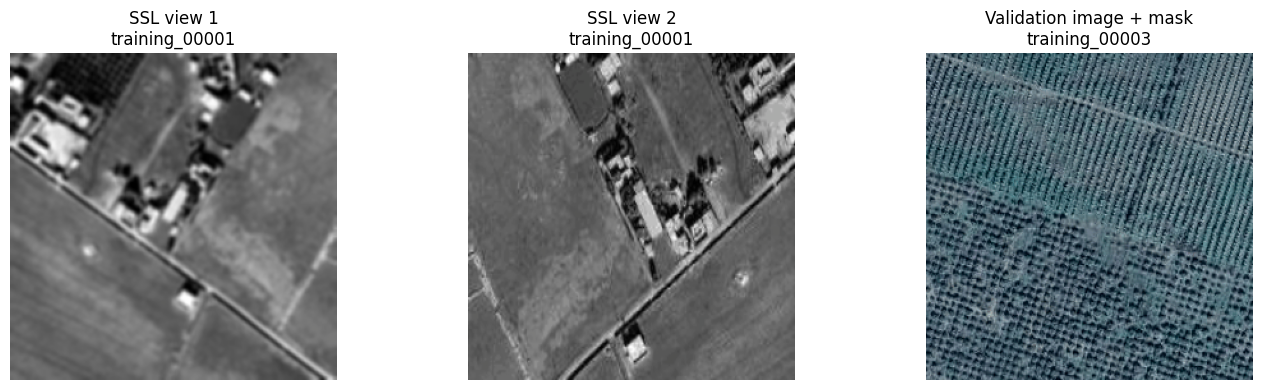

Saved sanity visualization:
/kaggle/working/PartB_NB0_DataPrep_outputs/taskA_sanity_visualization.png


In [19]:
# Cell 19 - Show required Task-A sanity visualization

# Get two augmented SSL views from the same train image.
view_1, view_2, ssl_image_id = ssl_train_dataset[0]

# Get one validation image and mask.
val_image, val_mask, val_image_id = finetune_dataset[0]

# Convert tensors to displayable images.
view_1_rgb = denormalize_tensor(view_1)
view_2_rgb = denormalize_tensor(view_2)
val_rgb = denormalize_tensor(val_image)

# Create mask overlay.
val_overlay = overlay_mask(
    rgb_image=val_rgb,
    mask=val_mask.numpy(),
)

# Plot required sanity check.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(view_1_rgb)
axes[0].set_title(f"SSL view 1\n{ssl_image_id}")
axes[0].axis("off")

axes[1].imshow(view_2_rgb)
axes[1].set_title(f"SSL view 2\n{ssl_image_id}")
axes[1].axis("off")

axes[2].imshow(val_overlay)
axes[2].set_title(f"Validation image + mask\n{val_image_id}")
axes[2].axis("off")

plt.tight_layout()

# Save figure for report and viva.
sanity_path = OUTPUT_ROOT / "taskA_sanity_visualization.png"
plt.savefig(sanity_path, dpi=160)

plt.show()

print("Saved sanity visualization:")
print(sanity_path)

In [20]:
# Cell 20 - Save final README and zip shared outputs

readme_text = f"""
Part B NB0 Data Prep Output

Dataset: {DATASET_NAME}

Role mapping:
- Part-A train split -> unlabelled SSL pretraining: {len(train_ssl_df)} images
- Part-A validation split -> labelled fine-tuning: {len(val_finetune_df)} images
- Part-A test split -> monitoring + final evaluation: {len(test_eval_df)} images

Important:
- No new split was created.
- All SSL methods must load these shared files.
- Train split uses images only for SSL.
- Validation/test splits use image + mask.
""".strip()

readme_path = SHARED_ROOT / "README_partb_shared.md"

with open(readme_path, "w") as file:
    file.write(readme_text)

zip_path = shutil.make_archive(
    str(OUTPUT_ROOT / "partb_shared_artifacts"),
    "zip",
    SHARED_ROOT,
)

print(readme_text)

print("\nSaved README:")
print(readme_path)

print("\nSaved zip:")
print(zip_path)

Part B NB0 Data Prep Output

Dataset: Moroccan Landing Site Segmentation V2

Role mapping:
- Part-A train split -> unlabelled SSL pretraining: 1416 images
- Part-A validation split -> labelled fine-tuning: 314 images
- Part-A test split -> monitoring + final evaluation: 360 images

Important:
- No new split was created.
- All SSL methods must load these shared files.
- Train split uses images only for SSL.
- Validation/test splits use image + mask.

Saved README:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/README_partb_shared.md

Saved zip:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared_artifacts.zip


In [21]:
# Cell 21 - Final checklist for Part B NB0 Data Prep

print("PART B NB0 DATA PREP FINAL CHECK")

print("\nRequired outputs:")

required_files = [
    SHARED_ROOT / "train_ssl_images.csv",
    SHARED_ROOT / "val_finetune_images_masks.csv",
    SHARED_ROOT / "test_monitor_eval_images_masks.csv",
    SHARED_ROOT / "split_role_mapping.csv",
    SHARED_ROOT / "all_splits_partb_copy.csv",
    SHARED_ROOT / "dataset_config.json",
    SHARED_ROOT / "class_names.json",
    SHARED_ROOT / "README_partb_shared.md",
]

for file_path in required_files:
    print(file_path.name, "exists:", file_path.exists())

print("\nVisualization exists:")
print((OUTPUT_ROOT / "taskA_sanity_visualization.png").exists())

print("\nSplit counts:")
print("SSL train images:", len(train_ssl_df))
print("Fine-tune validation images:", len(val_finetune_df))
print("Test monitor/eval images:", len(test_eval_df))

print("\nNotebook status:")
print("Data Prep completed.")
print("No new split was created.")
print("This output should be added as input to SimCLR/BYOL/MAE/DINOv2 notebooks.")

PART B NB0 DATA PREP FINAL CHECK

Required outputs:
train_ssl_images.csv exists: True
val_finetune_images_masks.csv exists: True
test_monitor_eval_images_masks.csv exists: True
split_role_mapping.csv exists: True
all_splits_partb_copy.csv exists: True
dataset_config.json exists: True
class_names.json exists: True
README_partb_shared.md exists: True

Visualization exists:
True

Split counts:
SSL train images: 1416
Fine-tune validation images: 314
Test monitor/eval images: 360

Notebook status:
Data Prep completed.
No new split was created.
This output should be added as input to SimCLR/BYOL/MAE/DINOv2 notebooks.


In [22]:
# Cell 22 - SimCLR augmentation pipeline

simclr_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.5, 1.0),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4,
        hue=0.1,
        p=0.8,
    ),
    A.ToGray(p=0.2),
    A.GaussianBlur(
        blur_limit=(3, 7),
        p=0.5,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

print("SimCLR augmentation ready.")
print("Input: train split images only")
print("Output: view_1, view_2, image_id")

SimCLR augmentation ready.
Input: train split images only
Output: view_1, view_2, image_id


In [23]:
# Cell 23 - Save SimCLR augmentation details

simclr_aug_info = {
    "method": "SimCLR",
    "input_split": "Part-A train split",
    "input_type": "images only, no masks",
    "output": "view_1, view_2, image_id",
    "purpose": "Create two strong augmented views for NT-Xent contrastive learning.",
    "augmentations": [
        "RandomResizedCrop",
        "HorizontalFlip",
        "ColorJitter",
        "ToGray",
        "GaussianBlur",
        "Normalize",
        "ToTensorV2",
    ],
    "notes": [
        "Masks are not used during SSL pretraining.",
        "Two views are generated from the same image.",
        "Other images in the batch act as negatives.",
    ],
}

simclr_aug_json_path = SHARED_ROOT / "simclr_augmentation.json"

with open(simclr_aug_json_path, "w") as file:
    json.dump(simclr_aug_info, file, indent=2)

simclr_aug_csv_path = SHARED_ROOT / "simclr_augmentation.csv"

pd.DataFrame({
    "augmentation": simclr_aug_info["augmentations"]
}).to_csv(simclr_aug_csv_path, index=False)

print("Saved:")
print(simclr_aug_json_path)
print(simclr_aug_csv_path)

Saved:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/simclr_augmentation.json
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/simclr_augmentation.csv


In [24]:
# Cell 24 - BYOL augmentation pipeline

byol_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.5, 1.0),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4,
        hue=0.1,
        p=0.8,
    ),
    A.ToGray(p=0.2),
    A.GaussianBlur(
        blur_limit=(3, 7),
        p=0.5,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

print("BYOL augmentation ready.")
print("Input: train split images only")
print("Output: online_view, target_view, image_id")

BYOL augmentation ready.
Input: train split images only
Output: online_view, target_view, image_id


In [25]:
# Cell 25 - Save BYOL augmentation details

byol_aug_info = {
    "method": "BYOL",
    "input_split": "Part-A train split",
    "input_type": "images only, no masks",
    "output": "online_view, target_view, image_id",
    "purpose": "Create two augmented views for online and target networks.",
    "augmentations": [
        "RandomResizedCrop",
        "HorizontalFlip",
        "ColorJitter",
        "ToGray",
        "GaussianBlur",
        "Normalize",
        "ToTensorV2",
    ],
    "notes": [
        "Masks are not used during BYOL SSL pretraining.",
        "BYOL does not use negative pairs.",
        "Target network is updated using EMA from the online network.",
    ],
}

byol_aug_json_path = SHARED_ROOT / "byol_augmentation.json"

with open(byol_aug_json_path, "w") as file:
    json.dump(byol_aug_info, file, indent=2)

byol_aug_csv_path = SHARED_ROOT / "byol_augmentation.csv"

pd.DataFrame({
    "augmentation": byol_aug_info["augmentations"]
}).to_csv(byol_aug_csv_path, index=False)

print("Saved:")
print(byol_aug_json_path)
print(byol_aug_csv_path)

Saved:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/byol_augmentation.json
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/byol_augmentation.csv


In [26]:
# Cell 26 - MAE augmentation pipeline

# MAE uses one image view.
# Patch masking is done inside the MAE model/training step.
mae_transform = A.Compose([
    A.Resize(
        IMAGE_SIZE,
        IMAGE_SIZE,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Recommended MAE masking setting.
MAE_MASK_RATIO = 0.75

print("MAE augmentation ready.")
print("Input: train split images only")
print("Output: image_tensor, image_id")
print("Patch masking ratio:", MAE_MASK_RATIO)

MAE augmentation ready.
Input: train split images only
Output: image_tensor, image_id
Patch masking ratio: 0.75


In [27]:
# Cell 27 - Save MAE augmentation details

mae_aug_info = {
    "method": "MAE",
    "input_split": "Part-A train split",
    "input_type": "images only, no masks",
    "output": "image_tensor, image_id",
    "purpose": "Prepare image tensor for masked-patch reconstruction.",
    "augmentations": [
        "Resize",
        "Normalize",
        "ToTensorV2",
    ],
    "masking": {
        "mask_ratio": MAE_MASK_RATIO,
        "description": "Randomly mask about 75% of image patches during MAE pretraining.",
    },
    "notes": [
        "MAE does not need two augmented views.",
        "Masking happens during MAE training, not as a saved image mask.",
        "Masks from semantic segmentation are not used during SSL pretraining.",
    ],
}

mae_aug_json_path = SHARED_ROOT / "mae_augmentation.json"

with open(mae_aug_json_path, "w") as file:
    json.dump(mae_aug_info, file, indent=2)

mae_aug_csv_path = SHARED_ROOT / "mae_augmentation.csv"

pd.DataFrame({
    "augmentation": mae_aug_info["augmentations"]
}).to_csv(mae_aug_csv_path, index=False)

print("Saved:")
print(mae_aug_json_path)
print(mae_aug_csv_path)

Saved:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/mae_augmentation.json
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/mae_augmentation.csv


In [28]:
# Cell 28 - DINOv2 augmentation pipeline

# Global crops: larger views of the image.
dinov2_global_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.5, 1.0),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.2,
        hue=0.1,
        p=0.8,
    ),
    A.GaussianBlur(
        blur_limit=(3, 7),
        p=0.5,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Local crops: smaller views, resized back to IMAGE_SIZE.
dinov2_local_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.15, 0.5),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.2,
        hue=0.1,
        p=0.8,
    ),
    A.GaussianBlur(
        blur_limit=(3, 7),
        p=0.5,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Typical DINO-style crop counts.
DINO_NUM_GLOBAL_CROPS = 2
DINO_NUM_LOCAL_CROPS = 4

print("DINOv2 augmentation ready.")
print("Input: train split images only")
print("Output: list_of_crops, image_id")
print("Global crops:", DINO_NUM_GLOBAL_CROPS)
print("Local crops:", DINO_NUM_LOCAL_CROPS)

DINOv2 augmentation ready.
Input: train split images only
Output: list_of_crops, image_id
Global crops: 2
Local crops: 4


In [29]:
# Cell 29 - Save DINOv2 augmentation details

dinov2_aug_info = {
    "method": "DINOv2",
    "input_split": "Part-A train split",
    "input_type": "images only, no masks",
    "output": "list_of_crops, image_id",
    "purpose": "Create global and local crops for self-distillation.",
    "augmentations": [
        "RandomResizedCrop_global",
        "RandomResizedCrop_local",
        "HorizontalFlip",
        "ColorJitter",
        "GaussianBlur",
        "Normalize",
        "ToTensorV2",
    ],
    "crop_settings": {
        "num_global_crops": DINO_NUM_GLOBAL_CROPS,
        "num_local_crops": DINO_NUM_LOCAL_CROPS,
        "global_crop_scale": "0.5 to 1.0",
        "local_crop_scale": "0.15 to 0.5",
    },
    "notes": [
        "Masks are not used during DINOv2 SSL pretraining.",
        "Global crops provide larger scene context.",
        "Local crops encourage local feature consistency.",
        "Teacher network is updated from the student using EMA in DINO-style training.",
    ],
}

dinov2_aug_json_path = SHARED_ROOT / "dinov2_augmentation.json"

with open(dinov2_aug_json_path, "w") as file:
    json.dump(dinov2_aug_info, file, indent=2)

dinov2_aug_csv_path = SHARED_ROOT / "dinov2_augmentation.csv"

pd.DataFrame({
    "augmentation": dinov2_aug_info["augmentations"]
}).to_csv(dinov2_aug_csv_path, index=False)

print("Saved:")
print(dinov2_aug_json_path)
print(dinov2_aug_csv_path)

Saved:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/dinov2_augmentation.json
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/dinov2_augmentation.csv


,method,train_input,augmentation,output
0,SimCLR,train images only,"two strong views: crop, flip, jitter, grayscal...","view_1, view_2, image_id"
1,BYOL,train images only,two strong views for online and target networks,"online_view, target_view, image_id"
2,MAE,train images only,resize/normalize + 75% random patch masking du...,"image_tensor, image_id"
3,DINOv2,train images only,multi-crop: 2 global crops + 4 local crops,"list_of_crops, image_id"


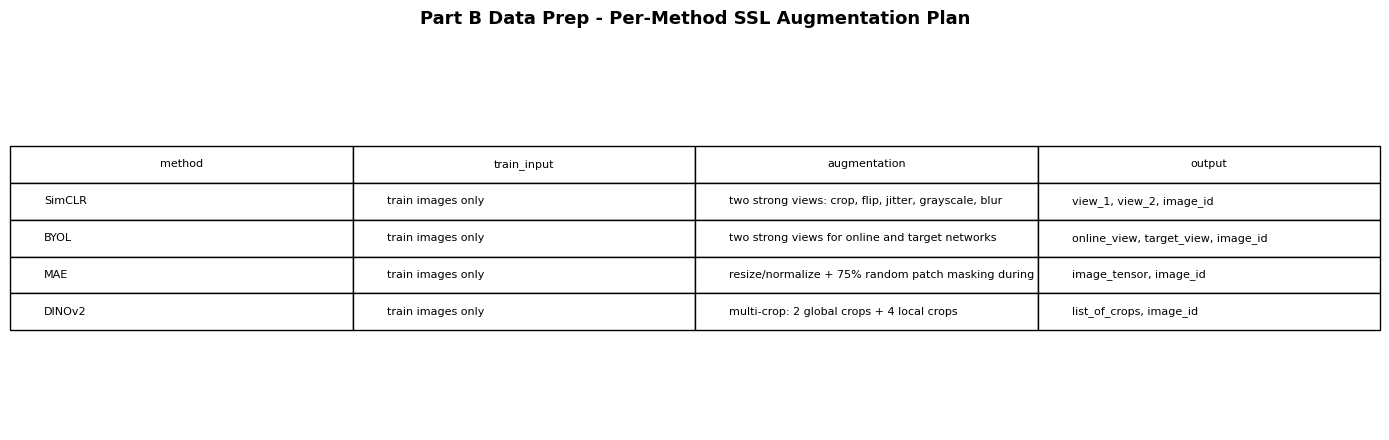

Saved combined augmentation CSV:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/per_method_augmentation_plan.csv

Saved combined augmentation JSON:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/per_method_augmentation_plan.json

Saved augmentation plan image:
/kaggle/working/PartB_NB0_DataPrep_outputs/per_method_augmentation_plan.png


In [30]:
# Cell 30 - Save combined augmentation table and image

combined_augmentation_plan = [
    {
        "method": "SimCLR",
        "train_input": "train images only",
        "augmentation": "two strong views: crop, flip, jitter, grayscale, blur",
        "output": "view_1, view_2, image_id",
    },
    {
        "method": "BYOL",
        "train_input": "train images only",
        "augmentation": "two strong views for online and target networks",
        "output": "online_view, target_view, image_id",
    },
    {
        "method": "MAE",
        "train_input": "train images only",
        "augmentation": "resize/normalize + 75% random patch masking during training",
        "output": "image_tensor, image_id",
    },
    {
        "method": "DINOv2",
        "train_input": "train images only",
        "augmentation": "multi-crop: 2 global crops + 4 local crops",
        "output": "list_of_crops, image_id",
    },
]

combined_aug_df = pd.DataFrame(combined_augmentation_plan)

combined_aug_csv_path = SHARED_ROOT / "per_method_augmentation_plan.csv"
combined_aug_json_path = SHARED_ROOT / "per_method_augmentation_plan.json"

combined_aug_df.to_csv(combined_aug_csv_path, index=False)

with open(combined_aug_json_path, "w") as file:
    json.dump(combined_augmentation_plan, file, indent=2)

display(combined_aug_df)

# Save table as image.
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.axis("off")

table = ax.table(
    cellText=combined_aug_df.values,
    colLabels=combined_aug_df.columns,
    cellLoc="left",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2.0)

ax.set_title(
    "Part B Data Prep - Per-Method SSL Augmentation Plan",
    fontsize=13,
    fontweight="bold",
    pad=16,
)

augmentation_image_path = OUTPUT_ROOT / "per_method_augmentation_plan.png"

plt.tight_layout()
plt.savefig(
    augmentation_image_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved combined augmentation CSV:")
print(combined_aug_csv_path)

print("\nSaved combined augmentation JSON:")
print(combined_aug_json_path)

print("\nSaved augmentation plan image:")
print(augmentation_image_path)

In [31]:
# Cell 31 - Copy images into shared folder and rebuild zip

# Copy Task-A sanity visualization into shared folder.
sanity_src = OUTPUT_ROOT / "taskA_sanity_visualization.png"
sanity_dst = SHARED_ROOT / "taskA_sanity_visualization.png"

if sanity_src.exists():
    shutil.copy2(sanity_src, sanity_dst)

# Copy augmentation plan image into shared folder.
augmentation_src = OUTPUT_ROOT / "per_method_augmentation_plan.png"
augmentation_dst = SHARED_ROOT / "per_method_augmentation_plan.png"

if augmentation_src.exists():
    shutil.copy2(augmentation_src, augmentation_dst)

# Update README with augmentation note.
readme_path = SHARED_ROOT / "README_partb_shared.md"

with open(readme_path, "a") as file:
    file.write("\n\nPer-method augmentation files included:\n")
    file.write("- simclr_augmentation.json / .csv\n")
    file.write("- byol_augmentation.json / .csv\n")
    file.write("- mae_augmentation.json / .csv\n")
    file.write("- dinov2_augmentation.json / .csv\n")
    file.write("- per_method_augmentation_plan.json / .csv / .png\n")

# Rebuild final zip from shared folder.
final_zip_path = shutil.make_archive(
    str(OUTPUT_ROOT / "partb_shared_artifacts"),
    "zip",
    SHARED_ROOT,
)

print("Copied images:")
print(" -", sanity_dst.name, "exists:", sanity_dst.exists())
print(" -", augmentation_dst.name, "exists:", augmentation_dst.exists())

print("\nUpdated README:")
print(readme_path)

print("\nFinal zip:")
print(final_zip_path)

Copied images:
 - taskA_sanity_visualization.png exists: True
 - per_method_augmentation_plan.png exists: True

Updated README:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared/README_partb_shared.md

Final zip:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared_artifacts.zip


In [32]:
# Cell 32 - Final checklist after augmentation updates

print("FINAL NB0 DATA PREP CHECK")

required_files = [
    "train_ssl_images.csv",
    "val_finetune_images_masks.csv",
    "test_monitor_eval_images_masks.csv",
    "split_role_mapping.csv",
    "all_splits_partb_copy.csv",
    "dataset_config.json",
    "class_names.json",
    "README_partb_shared.md",

    "simclr_augmentation.json",
    "simclr_augmentation.csv",
    "byol_augmentation.json",
    "byol_augmentation.csv",
    "mae_augmentation.json",
    "mae_augmentation.csv",
    "dinov2_augmentation.json",
    "dinov2_augmentation.csv",

    "per_method_augmentation_plan.csv",
    "per_method_augmentation_plan.json",
    "taskA_sanity_visualization.png",
    "per_method_augmentation_plan.png",
]

for file_name in required_files:
    file_path = SHARED_ROOT / file_name
    print(file_name, "exists:", file_path.exists())

print("\nFinal zip exists:")
print((OUTPUT_ROOT / "partb_shared_artifacts.zip").exists())

print("\nFinal counts:")
print("Train / SSL:", len(train_ssl_df))
print("Validation / fine-tune:", len(val_finetune_df))
print("Test / monitor+eval:", len(test_eval_df))

print("\nNB0 status:")
print("Data Prep completed.")
print("Split reused without reshuffling.")
print("Shared split files saved.")
print("Per-method augmentation plan saved.")
print("Notebook is ready for Save & Run All.")

FINAL NB0 DATA PREP CHECK
train_ssl_images.csv exists: True
val_finetune_images_masks.csv exists: True
test_monitor_eval_images_masks.csv exists: True
split_role_mapping.csv exists: True
all_splits_partb_copy.csv exists: True
dataset_config.json exists: True
class_names.json exists: True
README_partb_shared.md exists: True
simclr_augmentation.json exists: True
simclr_augmentation.csv exists: True
byol_augmentation.json exists: True
byol_augmentation.csv exists: True
mae_augmentation.json exists: True
mae_augmentation.csv exists: True
dinov2_augmentation.json exists: True
dinov2_augmentation.csv exists: True
per_method_augmentation_plan.csv exists: True
per_method_augmentation_plan.json exists: True
taskA_sanity_visualization.png exists: True
per_method_augmentation_plan.png exists: True

Final zip exists:
True

Final counts:
Train / SSL: 1416
Validation / fine-tune: 314
Test / monitor+eval: 360

NB0 status:
Data Prep completed.
Split reused without reshuffling.
Shared split files saved

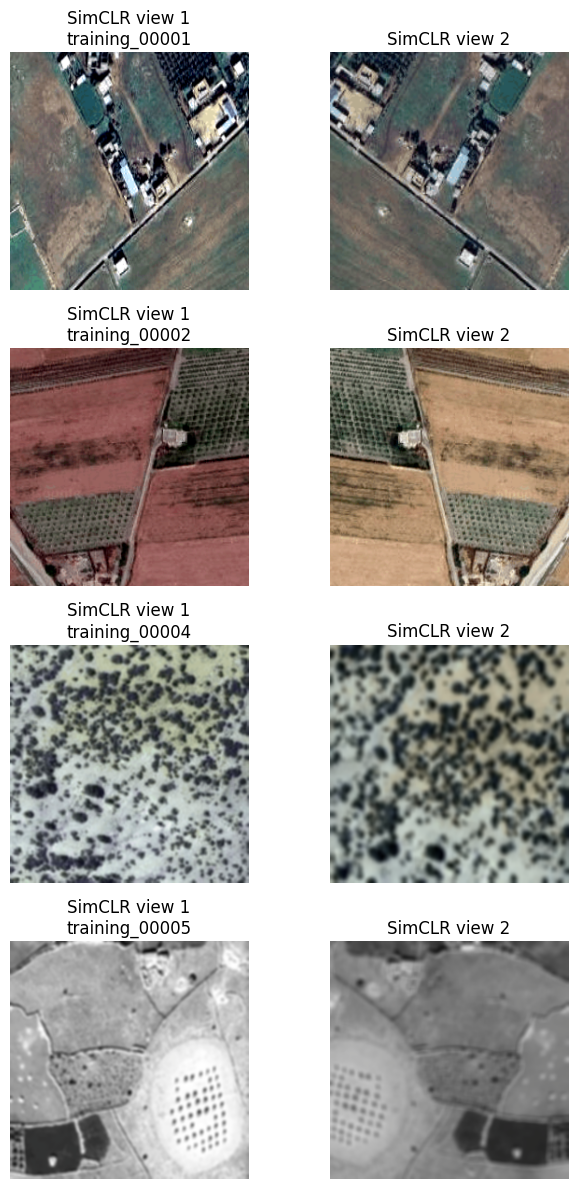

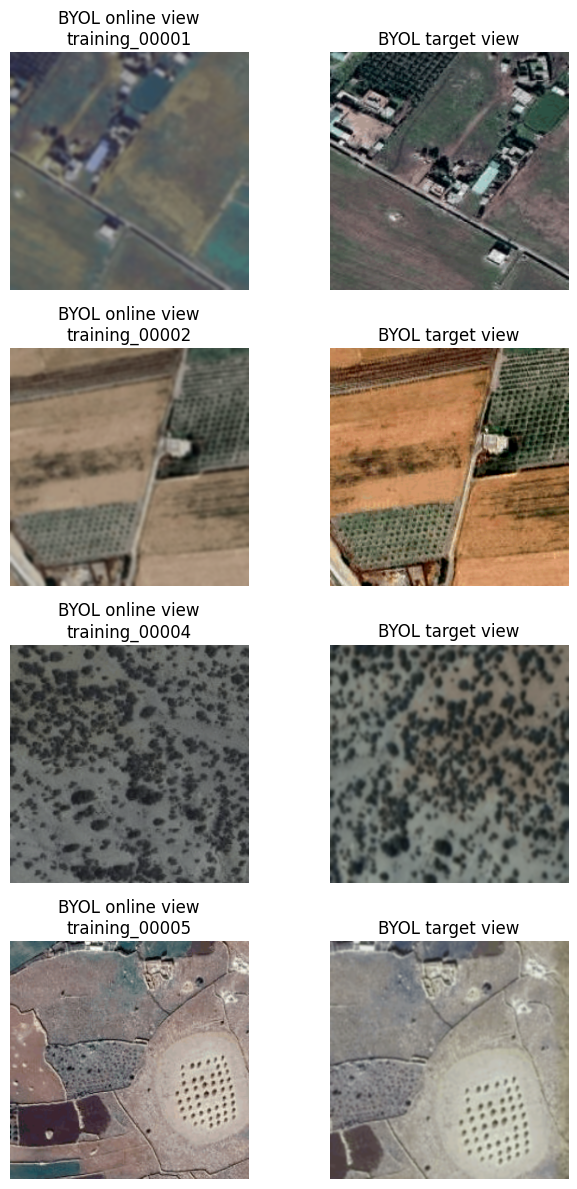

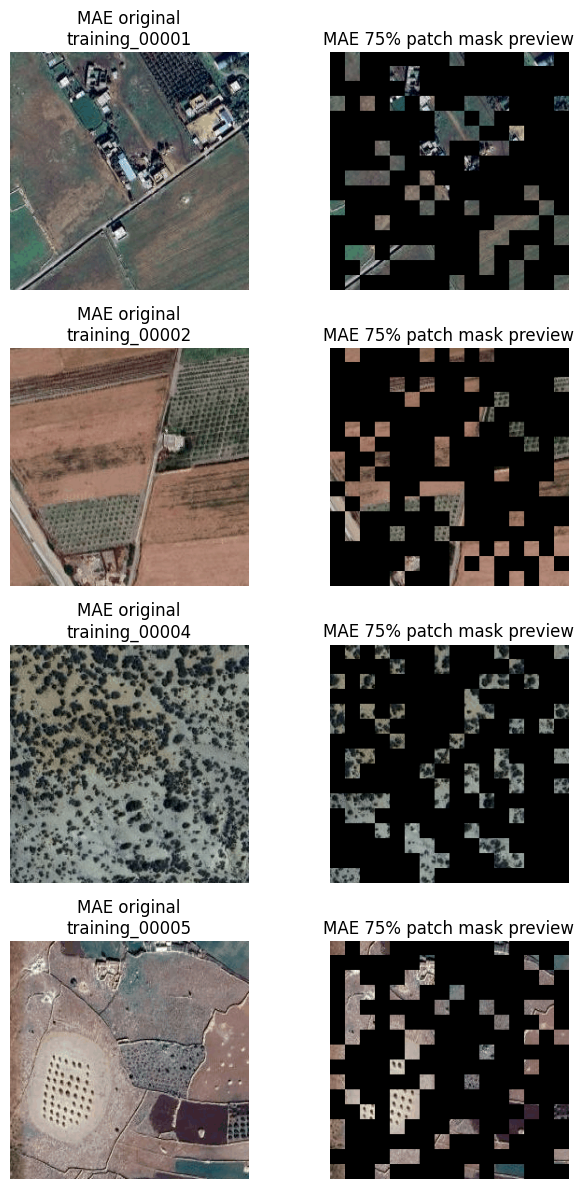

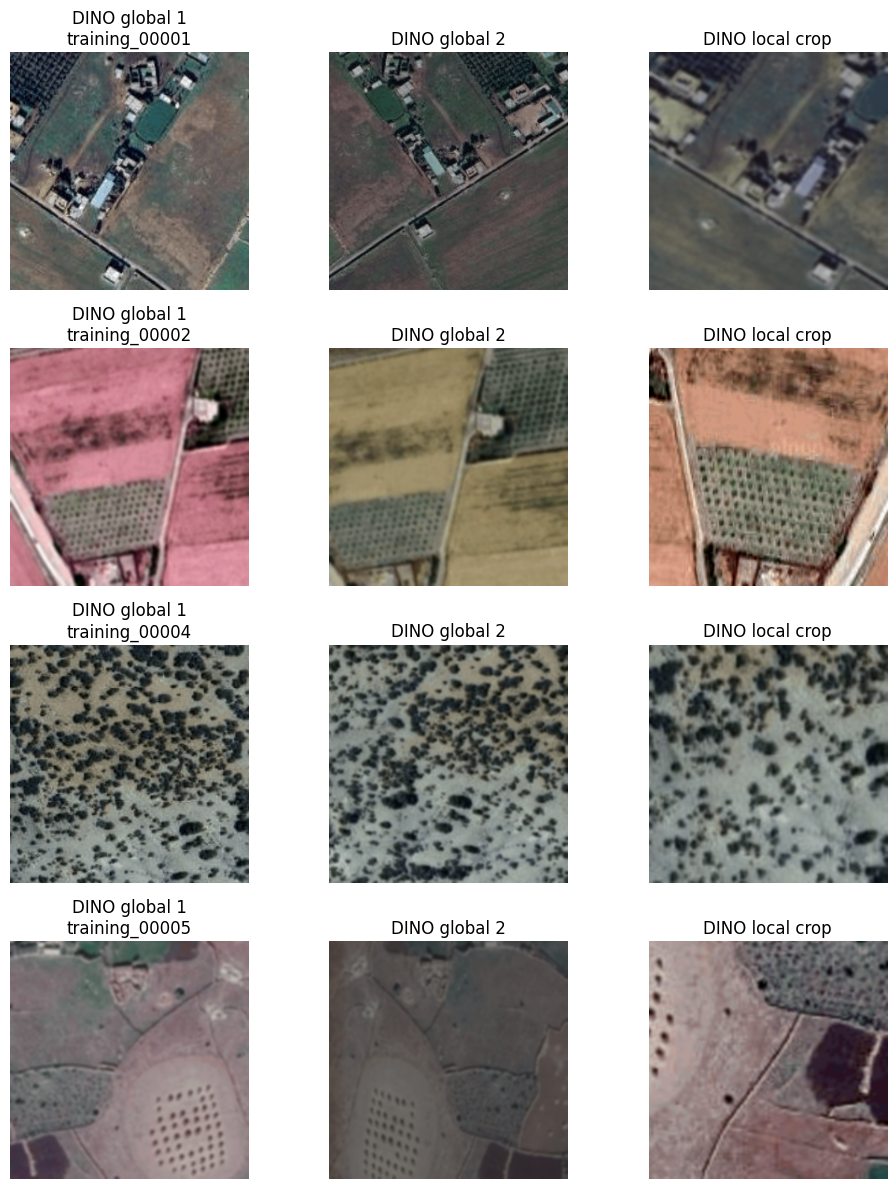

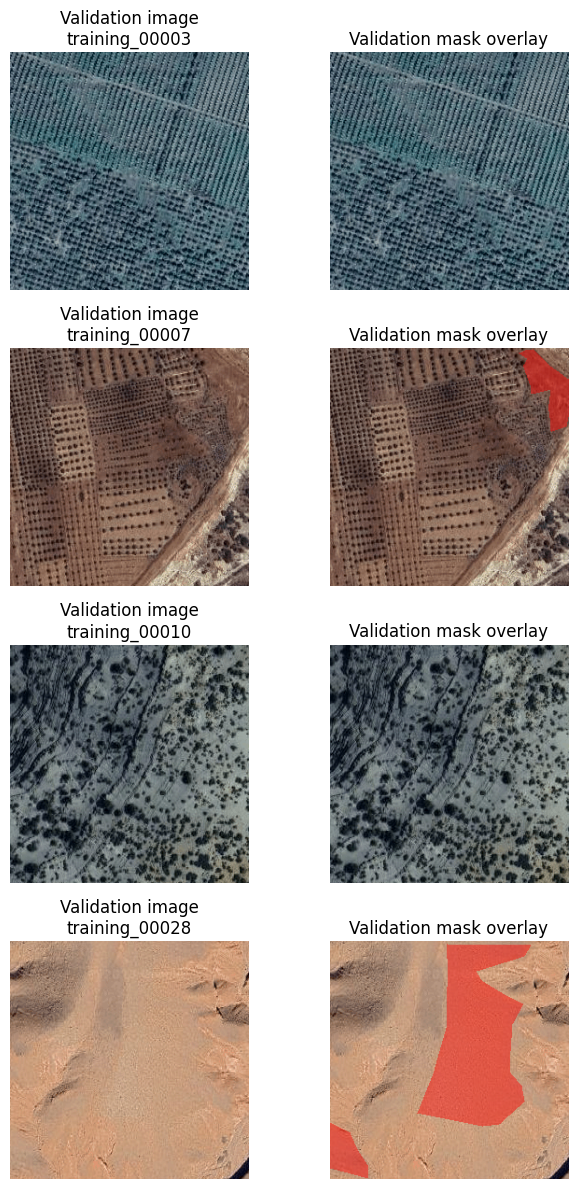

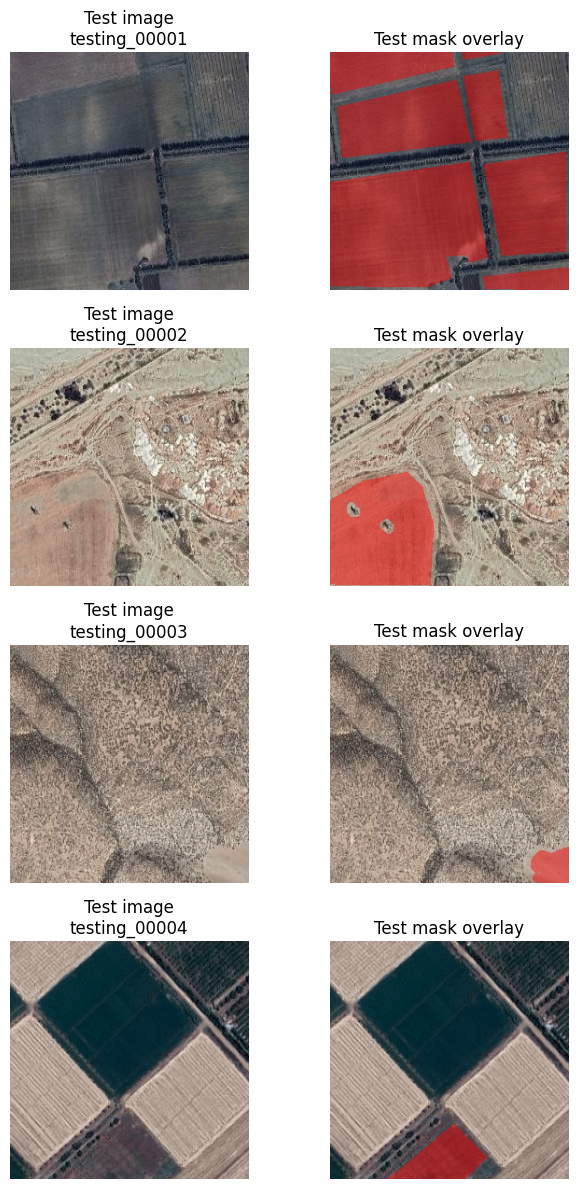

Saved preview grids:
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/simclr_preview_grid.png
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/byol_preview_grid.png
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/mae_preview_grid.png
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/dinov2_preview_grid.png
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/validation_overlay_preview.png
/kaggle/working/PartB_NB0_DataPrep_outputs/augmentation_previews/test_overlay_preview.png


In [33]:
# Cell 33 - Save preview grids for SSL augmentations and val/test overlays

PREVIEW_COUNT = 4

preview_root = OUTPUT_ROOT / "augmentation_previews"
preview_root.mkdir(parents=True, exist_ok=True)


# Helper: convert normalized tensor to RGB image.
def tensor_to_rgb(image_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = image_tensor.cpu() * std + mean
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0).numpy()

    return image


# Helper: overlay binary mask in red.
def make_overlay(rgb_image, mask, alpha=0.45):
    rgb_image = rgb_image.copy()

    red = np.zeros_like(rgb_image)
    red[..., 0] = 1.0

    mask_area = mask > 0

    rgb_image[mask_area] = (
        (1 - alpha) * rgb_image[mask_area]
        + alpha * red[mask_area]
    )

    return rgb_image


# -----------------------------
# 1. SimCLR preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 2, figsize=(7, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = train_ssl_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])

    view_1 = simclr_transform(image=image)["image"]
    view_2 = simclr_transform(image=image)["image"]

    axes[i, 0].imshow(tensor_to_rgb(view_1))
    axes[i, 0].set_title(f"SimCLR view 1\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(tensor_to_rgb(view_2))
    axes[i, 1].set_title("SimCLR view 2")
    axes[i, 1].axis("off")

plt.tight_layout()
simclr_preview_path = preview_root / "simclr_preview_grid.png"
plt.savefig(simclr_preview_path, dpi=160)
plt.show()


# -----------------------------
# 2. BYOL preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 2, figsize=(7, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = train_ssl_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])

    online_view = byol_transform(image=image)["image"]
    target_view = byol_transform(image=image)["image"]

    axes[i, 0].imshow(tensor_to_rgb(online_view))
    axes[i, 0].set_title(f"BYOL online view\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(tensor_to_rgb(target_view))
    axes[i, 1].set_title("BYOL target view")
    axes[i, 1].axis("off")

plt.tight_layout()
byol_preview_path = preview_root / "byol_preview_grid.png"
plt.savefig(byol_preview_path, dpi=160)
plt.show()


# -----------------------------
# 3. MAE preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 2, figsize=(7, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = train_ssl_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])

    image_tensor = mae_transform(image=image)["image"]
    image_rgb = tensor_to_rgb(image_tensor)

    # Visual-only random patch mask preview.
    patch_size = 16
    masked_rgb = image_rgb.copy()

    h, w, _ = masked_rgb.shape
    num_patches_h = h // patch_size
    num_patches_w = w // patch_size

    total_patches = num_patches_h * num_patches_w
    num_masked = int(total_patches * MAE_MASK_RATIO)

    patch_indices = np.random.choice(
        total_patches,
        size=num_masked,
        replace=False,
    )

    for patch_index in patch_indices:
        py = patch_index // num_patches_w
        px = patch_index % num_patches_w

        y1 = py * patch_size
        y2 = y1 + patch_size
        x1 = px * patch_size
        x2 = x1 + patch_size

        masked_rgb[y1:y2, x1:x2, :] = 0.0

    axes[i, 0].imshow(image_rgb)
    axes[i, 0].set_title(f"MAE original\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masked_rgb)
    axes[i, 1].set_title("MAE 75% patch mask preview")
    axes[i, 1].axis("off")

plt.tight_layout()
mae_preview_path = preview_root / "mae_preview_grid.png"
plt.savefig(mae_preview_path, dpi=160)
plt.show()


# -----------------------------
# 4. DINOv2 preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 3, figsize=(10, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = train_ssl_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])

    global_crop_1 = dinov2_global_transform(image=image)["image"]
    global_crop_2 = dinov2_global_transform(image=image)["image"]
    local_crop = dinov2_local_transform(image=image)["image"]

    axes[i, 0].imshow(tensor_to_rgb(global_crop_1))
    axes[i, 0].set_title(f"DINO global 1\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(tensor_to_rgb(global_crop_2))
    axes[i, 1].set_title("DINO global 2")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(tensor_to_rgb(local_crop))
    axes[i, 2].set_title("DINO local crop")
    axes[i, 2].axis("off")

plt.tight_layout()
dinov2_preview_path = preview_root / "dinov2_preview_grid.png"
plt.savefig(dinov2_preview_path, dpi=160)
plt.show()


# -----------------------------
# 5. Validation overlay preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 2, figsize=(7, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = val_finetune_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])
    mask = read_mask(NB0_OUTPUT_ROOT / row["encoded_mask_relpath"])

    transformed = test_transform(image=image, mask=mask)
    rgb = tensor_to_rgb(transformed["image"])
    mask_arr = transformed["mask"].numpy()

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Validation image\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(make_overlay(rgb, mask_arr))
    axes[i, 1].set_title("Validation mask overlay")
    axes[i, 1].axis("off")

plt.tight_layout()
val_preview_path = preview_root / "validation_overlay_preview.png"
plt.savefig(val_preview_path, dpi=160)
plt.show()


# -----------------------------
# 6. Test overlay preview
# -----------------------------
fig, axes = plt.subplots(PREVIEW_COUNT, 2, figsize=(7, 3 * PREVIEW_COUNT))

for i in range(PREVIEW_COUNT):
    row = test_eval_df.iloc[i]
    image = read_rgb(DATA_ROOT / row["image_relpath"])
    mask = read_mask(NB0_OUTPUT_ROOT / row["encoded_mask_relpath"])

    transformed = test_transform(image=image, mask=mask)
    rgb = tensor_to_rgb(transformed["image"])
    mask_arr = transformed["mask"].numpy()

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Test image\n{row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(make_overlay(rgb, mask_arr))
    axes[i, 1].set_title("Test mask overlay")
    axes[i, 1].axis("off")

plt.tight_layout()
test_preview_path = preview_root / "test_overlay_preview.png"
plt.savefig(test_preview_path, dpi=160)
plt.show()


print("Saved preview grids:")
print(simclr_preview_path)
print(byol_preview_path)
print(mae_preview_path)
print(dinov2_preview_path)
print(val_preview_path)
print(test_preview_path)

In [34]:
# Cell 34 - Copy preview grids into shared folder and rebuild zip

# Create preview folder inside shared outputs.
shared_preview_root = SHARED_ROOT / "augmentation_previews"
shared_preview_root.mkdir(parents=True, exist_ok=True)

# Copy all preview PNG files.
preview_files = sorted(preview_root.glob("*.png"))

for preview_file in preview_files:
    shutil.copy2(
        preview_file,
        shared_preview_root / preview_file.name,
    )

# Rebuild final zip so preview images are included.
final_zip_path = shutil.make_archive(
    str(OUTPUT_ROOT / "partb_shared_artifacts"),
    "zip",
    SHARED_ROOT,
)

print("Copied preview files:", len(preview_files))

for preview_file in preview_files:
    print(" -", preview_file.name)

print("\nUpdated final zip:")
print(final_zip_path)

Copied preview files: 6
 - byol_preview_grid.png
 - dinov2_preview_grid.png
 - mae_preview_grid.png
 - simclr_preview_grid.png
 - test_overlay_preview.png
 - validation_overlay_preview.png

Updated final zip:
/kaggle/working/PartB_NB0_DataPrep_outputs/partb_shared_artifacts.zip


In [35]:
# Cell 35 - Final checklist including augmentation previews

print("FINAL NB0 DATA PREP CHECK")

required_files = [
    "train_ssl_images.csv",
    "val_finetune_images_masks.csv",
    "test_monitor_eval_images_masks.csv",
    "split_role_mapping.csv",
    "all_splits_partb_copy.csv",
    "dataset_config.json",
    "class_names.json",
    "README_partb_shared.md",

    "simclr_augmentation.json",
    "simclr_augmentation.csv",
    "byol_augmentation.json",
    "byol_augmentation.csv",
    "mae_augmentation.json",
    "mae_augmentation.csv",
    "dinov2_augmentation.json",
    "dinov2_augmentation.csv",

    "per_method_augmentation_plan.csv",
    "per_method_augmentation_plan.json",
    "taskA_sanity_visualization.png",
    "per_method_augmentation_plan.png",
]

print("\nRequired shared files:")

for file_name in required_files:
    file_path = SHARED_ROOT / file_name
    print(file_name, "exists:", file_path.exists())

print("\nPreview grid files:")

required_preview_files = [
    "simclr_preview_grid.png",
    "byol_preview_grid.png",
    "mae_preview_grid.png",
    "dinov2_preview_grid.png",
    "validation_overlay_preview.png",
    "test_overlay_preview.png",
]

for file_name in required_preview_files:
    file_path = SHARED_ROOT / "augmentation_previews" / file_name
    print(file_name, "exists:", file_path.exists())

print("\nFinal zip exists:")
print((OUTPUT_ROOT / "partb_shared_artifacts.zip").exists())

print("\nFinal counts:")
print("Train / SSL:", len(train_ssl_df))
print("Validation / fine-tune:", len(val_finetune_df))
print("Test / monitor+eval:", len(test_eval_df))

print("\nNB0 status:")
print("Data Prep completed.")
print("Split reused without reshuffling.")
print("Shared split files saved.")
print("Per-method augmentation plan saved.")
print("Preview grids saved.")
print("Notebook is ready for Save & Run All.")

FINAL NB0 DATA PREP CHECK

Required shared files:
train_ssl_images.csv exists: True
val_finetune_images_masks.csv exists: True
test_monitor_eval_images_masks.csv exists: True
split_role_mapping.csv exists: True
all_splits_partb_copy.csv exists: True
dataset_config.json exists: True
class_names.json exists: True
README_partb_shared.md exists: True
simclr_augmentation.json exists: True
simclr_augmentation.csv exists: True
byol_augmentation.json exists: True
byol_augmentation.csv exists: True
mae_augmentation.json exists: True
mae_augmentation.csv exists: True
dinov2_augmentation.json exists: True
dinov2_augmentation.csv exists: True
per_method_augmentation_plan.csv exists: True
per_method_augmentation_plan.json exists: True
taskA_sanity_visualization.png exists: True
per_method_augmentation_plan.png exists: True

Preview grid files:
simclr_preview_grid.png exists: True
byol_preview_grid.png exists: True
mae_preview_grid.png exists: True
dinov2_preview_grid.png exists: True
validation_ove